In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 28.8 MB/s eta 0:00:00


In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors, Crippen, Lipinski
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator



In [3]:
drugs = {
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "Caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "Ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
    "Acetaminophen": "CC(=O)Nc1ccc(O)cc1",
    "Metformin": "CN(C)C(=N)NC(=N)N",
    "Amoxicillin": "CC1(C)S[C@@H]2[C@H](NC(=O)[C@H](N)c3ccc(O)cc3)C(=O)N2[C@H]1C(=O)O",
    "Atorvastatin": "CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F)cc2)n1CC[C@@H](O)C[C@@H](O)CC(=O)O",
    "Metoprolol": "COCCc1ccc(OCC(O)CNC(C)C)cc1",
    "Omeprazole": "COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1",
    "Losartan": "CCCCc1nc(Cl)c(CO)n1Cc1ccc(-c2ccccc2-c2nnn[nH]2)cc1",
    "Albuterol": "CC(C)(C)NCC(O)c1ccc(O)c(CO)c1",
    "Fluoxetine": "CNCCC(Oc1ccc(C(F)(F)F)cc1)c1ccccc1",
    "Diazepam": "CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc21",
    "Ciprofloxacin": "O=C(O)c1cn(C2CC2)c2cc(N3CCNCC3)c(F)cc2c1=O",
    "Metronidazole": "Cc1ncc([N+](=O)[O-])n1CCO",
    "Amlodipine": "CCOC(=O)C1=C(COCCN)NC(C)=C(C(=O)OC)C1c1ccccc1Cl",
    "Warfarin": "CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O",
    "Gabapentin": "NCC1(CC(=O)O)CCCCC1",
    "Sildenafil": "CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12",
    "Penicillin G": "CC1(C)S[C@@H]2[C@H](NC(=O)Cc3ccccc3)C(=O)N2[C@H]1C(=O)O",
    "Morphine": "CN1CC[C@]23c4c5ccc(O)c4O[C@H]2[C@@H](O)C=C[C@H]3[C@H]1C5",
    "Penicillin Calcium": "CC1(C)S[C@@H]2[C@H](NC(=O)Cc3ccccc3)C(=O)N2[C@H]1C(=O)[O-].CC1(C)S[C@@H]2[C@H](NC(=O)Cc3ccccc3)C(=O)N2[C@H]1C(=O)[O-].[Ca+2]",
    "Methotrexate": "CN(Cc1cnc2nc(N)nc(N)c2n1)c1ccc(C(=O)N[C@@H](CCC(=O)O)C(=O)O)cc1",
    "Melatonin": "COc1ccc2[nH]cc(CCNC(C)=O)c2c1"
}

In [4]:
def drugs_info(name, smails):
  mol = Chem.MolFromSmiles(smails)
  Mw = Descriptors.MolWt(mol)
  LogP = Crippen.MolLogP(mol)
  HBD = Lipinski.NumHDonors(mol)
  HBA = Lipinski.NumHAcceptors(mol)
  return name, smails, Mw, LogP, HBD, HBA


drugs_info_list = []
for name, smails in drugs.items():
  drugs_info_list.append(drugs_info(name, smails))


df = pd.DataFrame(drugs_info_list, columns=['Drug', 'SMILES', 'Mw', 'LogP', 'HBD', 'HBA'])
df.to_csv('drugs.csv', index=False)

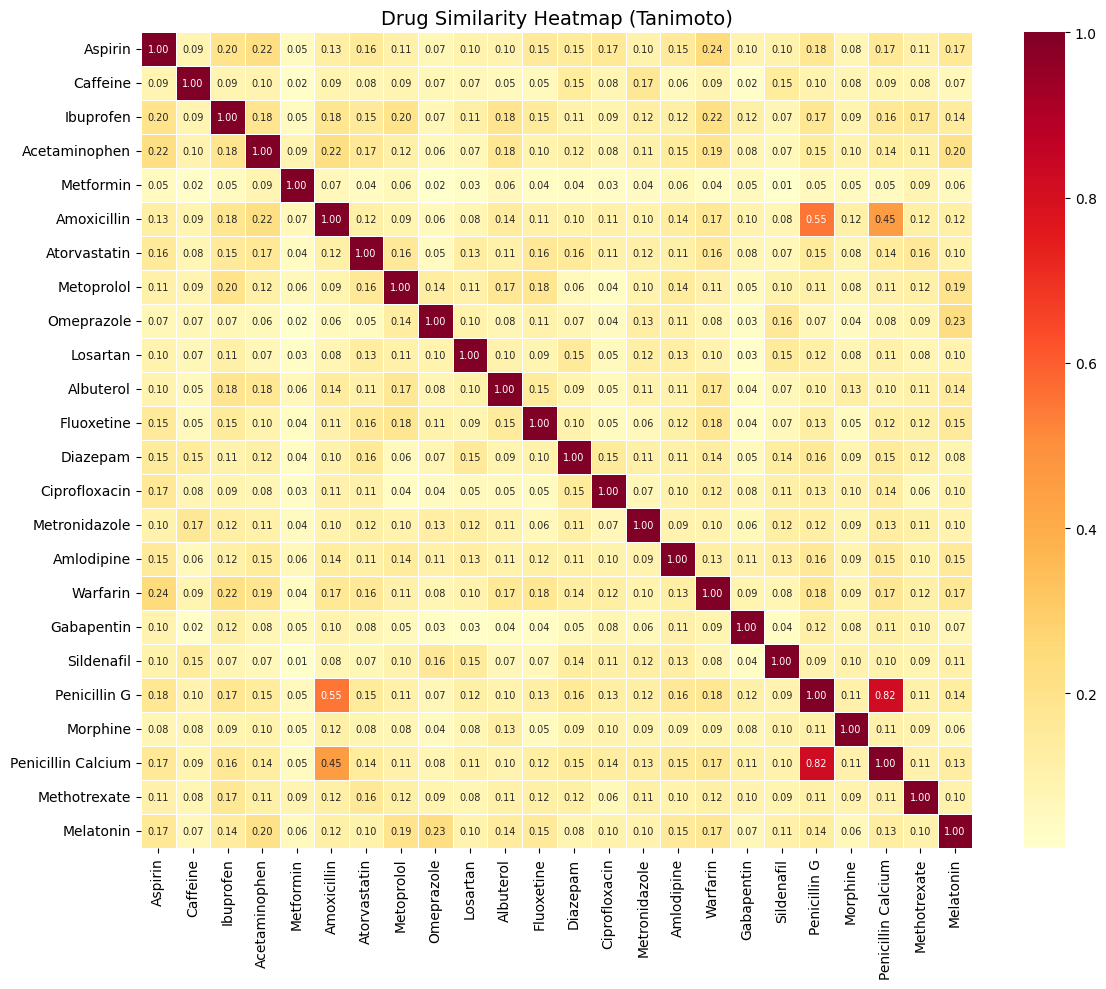

In [5]:
names = list(drugs.keys())
mols = [Chem.MolFromSmiles(smails) for smails in drugs.values()]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

fps = [gen.GetFingerprint(m) for m in mols]

n = len(drugs)
matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        matrix[i, j] = DataStructs.FingerprintSimilarity(fps[i], fps[j])

df = pd.DataFrame(matrix, index=names, columns=names)

plt.figure(figsize=(12, 10))
sns.heatmap(
    df,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    annot_kws={"size": 7}
)
plt.title("Drug Similarity Heatmap (Tanimoto)", fontsize=14)
plt.tight_layout()
plt.show()

In [6]:
np.fill_diagonal(matrix, 0)
idx = np.unravel_index(np.argmax(matrix, axis=None), matrix.shape)

print(f"Most Similar pair : {names[idx[0]]} & {names[idx[1]]}")
print(f"Similarity score : {matrix[idx]:.3f}")


Most Similar pair : Penicillin G & Penicillin Calcium
Similarity score : 0.816
